In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

%matplotlib inline
np.random.seed(42)

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
col_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
             'BMI', 'DiabetesPedigree', 'Age', 'Outcome']
df= pd.read_csv(url, names=col_names)
df.shape

(768, 9)

In [3]:
features_selection = ['Glucose', 'BMI', 'Age']
X = df[features_selection]
y = df['Outcome']

df_real = X.copy()
df_real['Diabete'] = y.map({0: 'Non', 1: 'Oui'})

print("=== APERÇU DE LA DATASET RÉELLE ===")
print(df_real.head())

=== APERÇU DE LA DATASET RÉELLE ===
   Glucose   BMI  Age Diabete
0      148  33.6   50     Oui
1       85  26.6   31     Non
2      183  23.3   32     Oui
3       89  28.1   21     Non
4      137  43.1   33     Oui


In [4]:
import seaborn as sns

# Le graphique suit automatiquement `features_selection` (2 ou 3 variables)
couleurs = {'Non': 'blue', 'Oui': 'red'}

if len(features_selection) == 3:
    f1, f2, f3 = features_selection
    fig = px.scatter_3d(
        df_real, x=f1, y=f2, z=f3,
        color='Diabete', color_discrete_map=couleurs,
        title='Pima Diabetes - Classes (Non / Oui)'
    )
    fig.update_traces(marker=dict(size=3))
    fig.show()
else:
    f1, f2 = features_selection[:2]
    sns.scatterplot(data=df_real, x=f1, y=f2, hue='Diabete',
                    palette=couleurs, s=60)
    plt.title('Pima Diabetes - Classes (Non / Oui)')
    plt.legend(title='Diabete')
    plt.show()

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression

# Choix du degré polynomial et de C par validation croisée
pipeline = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=5000))
])
param_grid = {
    'poly__degree': [1, 2, 3, 4],
    'logreg__C': [0.01, 0.1, 1, 10, 100]
}
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X, y)

best_degree = grid_search.best_params_['poly__degree']
print("Best degree:", best_degree)
print("Best C:", grid_search.best_params_['logreg__C'])
print("Best CV accuracy:", grid_search.best_score_)

Best degree: 3
Best C: 0.1
Best CV accuracy: 0.778677531618708


In [6]:
# Découpage AVANT toute transformation (pas de fuite de données)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Polynôme puis standardisation, ajustés sur le train uniquement
poly = PolynomialFeatures(degree=best_degree, include_bias=False)
scaler = StandardScaler()
X_train = scaler.fit_transform(poly.fit_transform(X_train_raw))
X_test = scaler.transform(poly.transform(X_test_raw))

# y en vecteur colonne (n, 1) pour correspondre à la sortie du modèle
y_train = y_train.to_numpy().reshape(-1, 1)
y_test = y_test.to_numpy().reshape(-1, 1)
print(X_train.shape, X_test.shape)

(614, 19) (154, 19)


In [7]:
def sigmoid(x):
    x = np.clip(x, -500, 500)  # évite le débordement de np.exp
    return 1 / (1 + np.exp(-x))

In [8]:
def initialisation(X):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return (W, b)


def modele(X, W, b):
    Z = X.dot(W) + b
    A = sigmoid(Z)
    return A

In [9]:
def log_loss(y, A, eps=1e-15):
    A = np.clip(A, eps, 1 - eps)  # évite log(0)
    return 1 / len(y) * np.sum(-y * np.log(A) - (1 - y) * np.log(1 - A))

In [10]:
def gradients(X, A, y):
    dW = 1 / len(y) * np.dot(X.T, A - y)
    db = 1 / len(y) * np.sum(A - y)
    return (dW, db)


def optimisation(X, W, b, A, y, learning_rate):
    dW, db = gradients(X, A, y)
    W = W - learning_rate * dW
    b = b - learning_rate * db
    return (W, b)

In [11]:
def predict(X, W, b, seuil=0.5):
    A = modele(X, W, b)
    return A >= seuil

In [12]:
def regression_logistique(X, y, learning_rate=0.1, n_iter=1000):
    # Initialisation
    W, b = initialisation(X)
    loss_history = []

    # Entraînement
    for i in range(n_iter):
        A = modele(X, W, b)
        loss_history.append(log_loss(y, A))
        W, b = optimisation(X, W, b, A, y, learning_rate=learning_rate)

    # Courbe de la fonction coût
    plt.plot(loss_history)
    plt.xlabel('n_iteration')
    plt.ylabel('Log_loss')
    plt.title('Evolution des erreurs')
    plt.show()
    return W, b

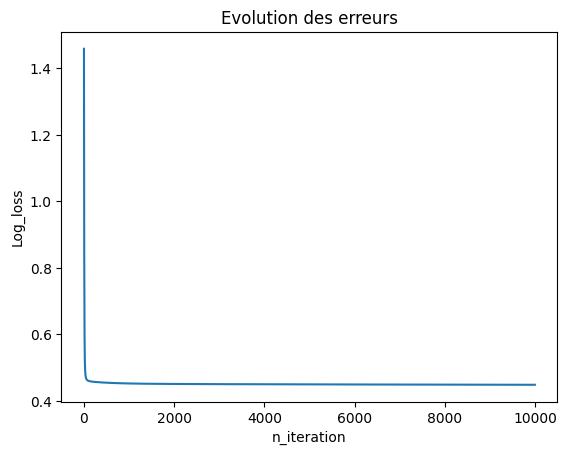

W = [ 0.2441017  -0.47688717  1.79300276  1.70370262 -0.59596735  0.48626061
  2.19211506  0.90381931 -0.16074314 -0.42682326  0.0925631   0.72906371
  0.5924118  -1.80732489 -0.82853777 -0.93740001 -0.46967927  0.63309451
 -1.32076595] | b = [-0.90604843]


In [13]:
W, b = regression_logistique(X_train, y_train, learning_rate=0.1, n_iter=10000)
print('W =', W.ravel(), '| b =', b)

In [14]:
y_train_pred = predict(X_train, W, b)
y_test_pred = predict(X_test, W, b)

# Accuracy calculée à la main
acc_train = np.mean(y_train_pred == y_train)
acc_test = np.mean(y_test_pred == y_test)
print(f"Accuracy train : {acc_train:.2%}")
print(f"Accuracy test  : {acc_test:.2%}")

Accuracy train : 79.48%
Accuracy test  : 72.08%


Accuracy  : 72.08%
Precision : 61.70%
Recall    : 53.70%
F1-score  : 57.43%


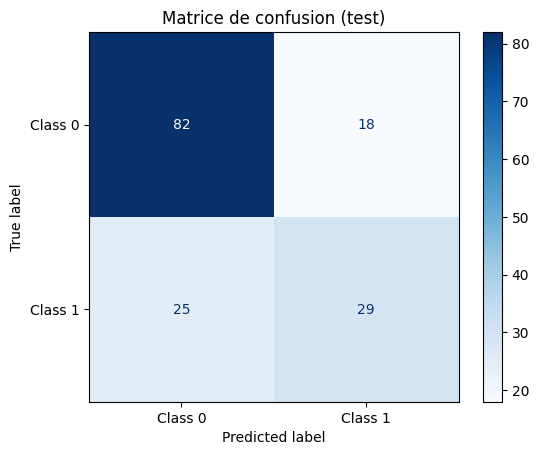

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

yt = y_test.ravel()
yp = y_test_pred.ravel().astype(int)

print(f"Accuracy  : {accuracy_score(yt, yp):.2%}")
print(f"Precision : {precision_score(yt, yp):.2%}")
print(f"Recall    : {recall_score(yt, yp):.2%}")
print(f"F1-score  : {f1_score(yt, yp):.2%}")

cm = confusion_matrix(yt, yp)
ConfusionMatrixDisplay(cm, display_labels=['Class 0', 'Class 1']).plot(cmap='Blues')
plt.title('Matrice de confusion (test)')
plt.show()

In [16]:
# Même graphique que le premier, avec la frontière de décision (proba = 0.5)
def proba(points):
    return modele(scaler.transform(poly.transform(points)), W, b)

couleurs = {'Non': 'blue', 'Oui': 'red'}

if len(features_selection) == 3:
    n = 30
    axes = [np.linspace(df_real[f].min(), df_real[f].max(), n) for f in features_selection]
    gx, gy, gz = np.meshgrid(*axes, indexing='ij')
    pts = pd.DataFrame(np.c_[gx.ravel(), gy.ravel(), gz.ravel()], columns=features_selection)
    P = proba(pts).ravel()

    fig = go.Figure()
    fig.add_trace(go.Isosurface(
        x=gx.ravel(), y=gy.ravel(), z=gz.ravel(), value=P,
        isomin=0.5, isomax=0.5, surface_count=1, opacity=0.4,
        colorscale=[[0, 'gray'], [1, 'gray']], showscale=False,
        caps=dict(x_show=False, y_show=False, z_show=False),
        name='Frontière', showlegend=True))
    for classe, couleur in couleurs.items():
        d = df_real[df_real['Diabete'] == classe]
        fig.add_trace(go.Scatter3d(
            x=d[features_selection[0]], y=d[features_selection[1]], z=d[features_selection[2]],
            mode='markers', marker=dict(size=3, color=couleur), name=classe))
    fig.update_layout(title='Pima Diabetes - Frontière de décision',
                      scene=dict(xaxis_title=features_selection[0],
                                 yaxis_title=features_selection[1],
                                 zaxis_title=features_selection[2]))
    fig.show()
else:
    f1, f2 = features_selection[:2]
    xx, yy = np.meshgrid(np.linspace(df_real[f1].min(), df_real[f1].max(), 400),
                         np.linspace(df_real[f2].min(), df_real[f2].max(), 400))
    pts = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=[f1, f2])
    Z = proba(pts).reshape(xx.shape)
    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, levels=[0, 0.5, 1], colors=['#cce0ff', '#ffcccc'], alpha=0.5)
    plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)
    sns.scatterplot(data=df_real, x=f1, y=f2, hue='Diabete', palette=couleurs, s=60)
    plt.title('Pima Diabetes - Frontière de décision')
    plt.show()